# `dict_to_vtk`

Exports a dictionary of 3D arrays into a single VTK ImageData (`.vti`) file that can be opened in ParaView or PyVista.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

import porespy as ps

ps.visualization.set_mpl_style()

## `data` and `filename`

Create a 3D porous image and a second scalar field (for example, the Euclidean distance transform), then export both arrays together in a single `.vti` file using `dict_to_vtk`. The `.vti` extension is appended automatically by `pyevtk`.

In [2]:
im = ps.generators.blobs(shape=[40, 40, 40], porosity=0.6, seed=0)
dt = ps.tools.get_edt()(im)

with tempfile.TemporaryDirectory() as tmpdir:
    fname = os.path.join(tmpdir, "blobs_fields")
    ps.io.dict_to_vtk(data={"void": im, "dt": dt}, filename=fname)
    vti_path = fname + ".vti"
    print(f"Written: {os.path.basename(vti_path)} ({os.path.getsize(vti_path):,} bytes)")
    grid = pv.read(vti_path)

print("Dimensions:", grid.dimensions)
print("Cell data arrays:", list(grid.cell_data.keys()))

Written: blobs_fields.vti (320,533 bytes)
Dimensions: (41, 41, 41)
Cell data arrays: ['void', 'dt']


Visualize a 2D slice of the two fields that were stored in the VTK file:

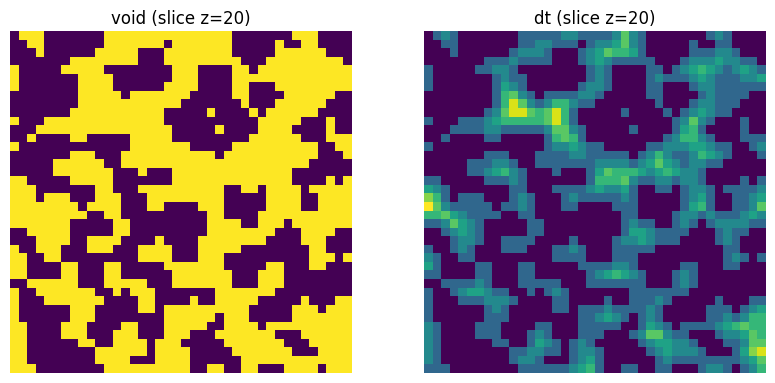

In [3]:
fig, ax = plt.subplots(1, 2, figsize=[10, 4])
ax[0].imshow(im[:, :, 20], origin="lower", interpolation="none")
ax[0].set_title("void (slice z=20)")
ax[0].axis(False)
ax[1].imshow(dt[:, :, 20], origin="lower", interpolation="none")
ax[1].set_title("dt (slice z=20)")
ax[1].axis(False);

## `voxel_size` and `origin`

Specify `voxel_size` and `origin` to store physical coordinates and spacing in the exported VTK grid:

In [4]:
with tempfile.TemporaryDirectory() as tmpdir:
    fname = os.path.join(tmpdir, "blobs_physical")
    ps.io.dict_to_vtk(
        data={"void": im, "dt": dt},
        filename=fname,
        voxel_size=2.5,
        origin=(10.0, 20.0, 30.0),
    )
    grid_phys = pv.read(fname + ".vti")

print("Spacing:", grid_phys.spacing)
print("Origin:", grid_phys.origin)

Spacing: (2.5, 2.5, 2.5)
Origin: (10.0, 20.0, 30.0)
